함수 및 패키지 호출

In [1]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

cuda
True
NVIDIA GeForce RTX 4080


In [2]:
import os.path
from pathlib import Path
from glob import glob

import json
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

import re
from soynlp.normalizer import repeat_normalize

import random
import string

from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, AutoConfig, DataCollatorWithPadding, AutoModelForCausalLM, BitsAndBytesConfig
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
from transformers import EarlyStoppingCallback
import torch.nn as nn
from transformers import AdamW
from transformers.modeling_outputs import SequenceClassifierOutput


device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
device

c:\Users\kimdd\anaconda3\envs\sangmin\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device(type='cuda', index=0)

In [3]:
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average = 'macro')
    acc = accuracy_score(labels, preds)

    return {'accuracy' : acc,
            'f1' : f1,
            'precision' : precision,
            'recall' : recall}

데이터 불러오기

In [4]:
whole_df = pd.read_csv('./whole.csv')

In [70]:
# 모델 불러오기
from transformers import ElectraModel, ElectraTokenizer, ElectraForSequenceClassification

MODEL_NAME =  "beomi/KcELECTRA-base-v2022" #"monologg/koelectra-base-v3-discriminator" "klue/roberta-base", "beomi/KcELECTRA-base-v2022", 'skt/kobert-base-v1', "monologg/distilkobert", "beomi/kobert", "distilbert/distilbert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

c:\Users\kimdd\anaconda3\envs\sangmin\lib\site-packages\huggingface_hub\file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [5]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME =  "bigscience/bloomz-560m"
tokenizer = AutoTokenizer.from_pretrained("bigscience/bloomz-560m") #"bigscience/bloomz-560m", "microsoft/deberta-v3-base", "google/fnet-base"
model = AutoModelForSequenceClassification.from_pretrained("bigscience/bloomz-560m")

c:\Users\kimdd\anaconda3\envs\sangmin\lib\site-packages\huggingface_hub\file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BloomForSequenceClassification were not initialized from the model checkpoint at bigscience/bloomz-560m and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Train, Valid, Test 분할

In [6]:
train_data = whole_df.sample(frac=0.6, random_state = 42)
remaining_data = whole_df.drop(train_data.index)

valid_data = remaining_data.sample(frac=0.3 / (0.3 + 0.1), random_state=42)
test_data = remaining_data.drop(valid_data.index)

In [7]:
new_textdata = pd.read_csv('new_testdata.csv')

In [8]:
# '0' label이 10,000개, '1' label이 6,301개가 되도록 합치기
label_0 = new_textdata[new_textdata['label'] == 0].sample(frac=1)
label_1 = new_textdata[new_textdata['label'] == 1].sample(frac=1)
label_2 = new_textdata[new_textdata['label'] == 2].sample(frac=1)
shuffled_df = pd.concat([label_0.head(100), label_1.head(100), label_2.head(100)]).sample(frac=1)

In [9]:
new_textdata = shuffled_df

MAX_LENGTH 확인

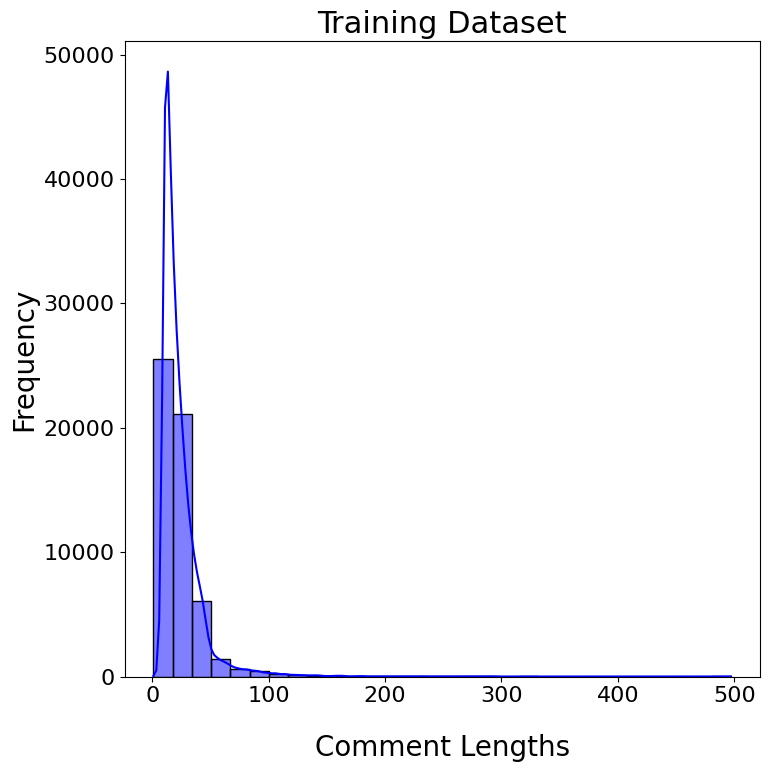

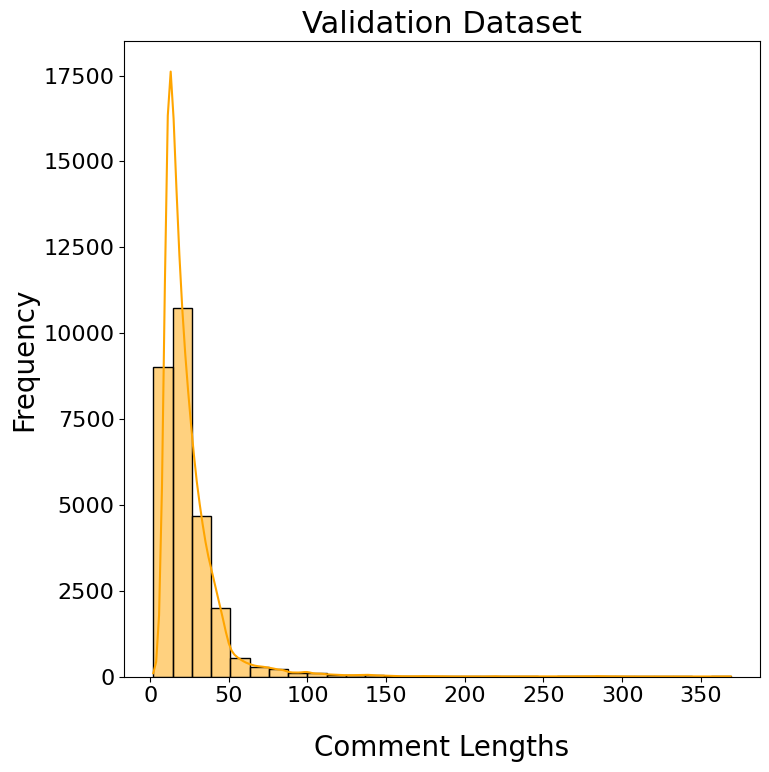

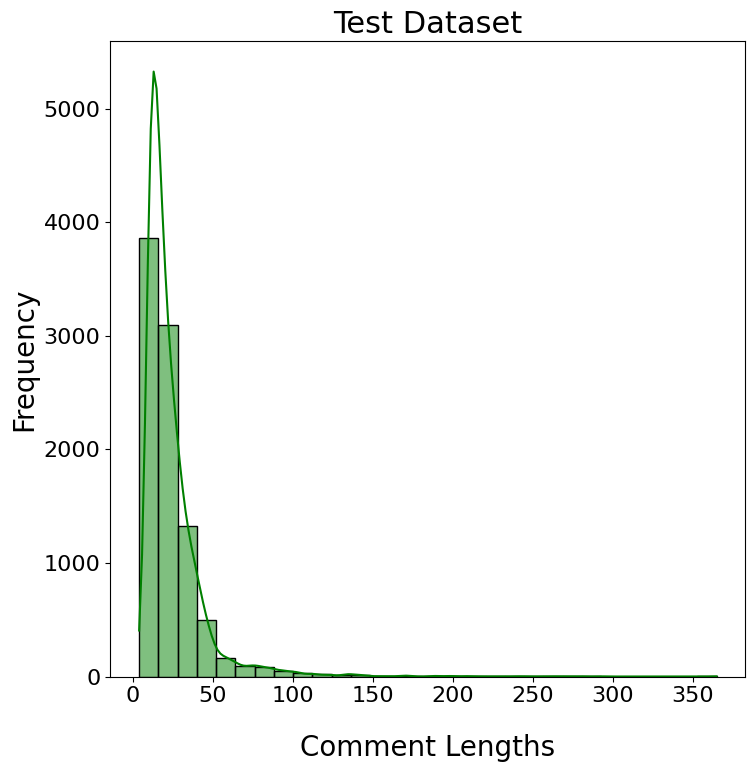

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# 전체 plot에 적용될 기본 폰트 크기
plt.rcParams.update({'font.size': 16})

# comment 길이 계산
train_data['comment_length'] = train_data['comment'].str.len()
valid_data['comment_length'] = valid_data['comment'].str.len()
test_data['comment_length'] = test_data['comment'].str.len()
new_textdata['comment_length'] = new_textdata['comment'].str.len()

def plot_and_save(data, title, filename, color):
    fig, ax = plt.subplots(figsize=(8, 8))  # 정사각형 figure
    sns.histplot(data=data, x='comment_length', bins=30, kde=True, color=color, ax=ax)
    ax.set_xlabel('Comment Lengths', fontsize=20, labelpad=20)
    ax.set_ylabel('Frequency', fontsize=20)
    ax.set_title(title, fontsize=22)
    ax.tick_params(axis='both', labelsize=16)
    ax.set_box_aspect(1)  # 플롯 박스를 정사각형으로
    plt.tight_layout()
    plt.savefig(filename, format='pdf')
    plt.show()

# 각 데이터셋에 대해 플롯 저장
plot_and_save(train_data, 'Training Dataset', 'train_comment_length.pdf', 'blue')
plot_and_save(valid_data, 'Validation Dataset', 'valid_comment_length.pdf', 'orange')
plot_and_save(test_data, 'Test Dataset', 'test_comment_length.pdf', 'green')
# plot_and_save(new_textdata, 'Distribution of Comment Lengths (New Text Data)', 'new_text_comment_length.pdf', 'green')


In [10]:
class CurseDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels # 입력에 대한 라벨받기
    
    def __getitem__(self, idx):
        # torch.tensor로 변환
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item
    
    def __len__(self):
        return len(self.labels)

토크나이징

In [11]:
tokenized_train_sentences = tokenizer(list(train_data['comment']),
                                      return_tensors = 'pt',
                                      max_length = 512,
                                      padding = True,
                                      truncation = True,
                                      add_special_tokens = True,)

In [12]:
tokenized_valid_sentences = tokenizer(list(valid_data['comment']),
                                      return_tensors = 'pt',
                                      max_length = 512,
                                      padding = True,
                                      truncation = True,
                                      add_special_tokens = True,)

In [13]:
tokenized_test_sentences = tokenizer(list(test_data['comment']),
                                      return_tensors = 'pt',
                                      max_length = 512,
                                      padding = True,
                                      truncation = True,
                                      add_special_tokens = True,)

In [14]:
tokenized_new_test_sentences = tokenizer(list(new_textdata['comment']),
                                      return_tensors = 'pt',
                                      max_length = 512,
                                      padding = True,
                                      truncation = True,
                                      add_special_tokens = True,)

In [15]:
from torch.utils.data import DataLoader

train_label = train_data['label'].values
valid_label = valid_data['label'].values
test_label = test_data['label'].values
new_test_label = new_textdata['label'].values

train_dataset = CurseDataset(tokenized_train_sentences, train_label)
valid_dataset = CurseDataset(tokenized_valid_sentences, valid_label)
test_dataset = CurseDataset(tokenized_test_sentences, test_label)
new_test_dataset = CurseDataset(tokenized_new_test_sentences, new_test_label)

모델 학습

In [16]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels = 3, problem_type = 'multi-label-classification', pad_token_id = 3)  

c:\Users\kimdd\anaconda3\envs\sangmin\lib\site-packages\huggingface_hub\file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BloomForSequenceClassification were not initialized from the model checkpoint at bigscience/bloomz-560m and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [59]:
model.to(device)

DebertaV2ForSequenceClassification(
  (deberta): DebertaV2Model(
    (embeddings): DebertaV2Embeddings(
      (word_embeddings): Embedding(128100, 1024, padding_idx=3)
      (LayerNorm): LayerNorm((1024,), eps=1e-07, elementwise_affine=True)
      (dropout): StableDropout()
    )
    (encoder): DebertaV2Encoder(
      (layer): ModuleList(
        (0-23): 24 x DebertaV2Layer(
          (attention): DebertaV2Attention(
            (self): DisentangledSelfAttention(
              (query_proj): Linear(in_features=1024, out_features=1024, bias=True)
              (key_proj): Linear(in_features=1024, out_features=1024, bias=True)
              (value_proj): Linear(in_features=1024, out_features=1024, bias=True)
              (pos_dropout): StableDropout()
              (dropout): StableDropout()
            )
            (output): DebertaV2SelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
              (LayerNorm): LayerNorm((1024,), eps=1e-07, element

In [60]:
from transformers import Trainer
import torch.nn as nn

# 손실함수 정의
class CustomTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False):
        labels = inputs.get("labels")
        # forward pass
        outputs = model(**inputs) 
        logits = outputs.get("logits")

        #class_weights = torch.tensor([2.0, 1.0, 1.0])  # Assuming 3 classes, adjust weights as needed
        #class_weights = class_weights.to(model.device)

        # compute categorical cross-entropy loss
        # 로짓을 재구성하여 손실함수에 맞게 형태를 맞추고 라벨을 1차원 텐서로 변환
        loss_fct = nn.CrossEntropyLoss().to(model.device)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))

        return (loss, outputs) if return_outputs else loss

In [61]:
training_args = TrainingArguments(output_dir = './deberta_data',
                                  num_train_epochs = 10,
                                  per_device_train_batch_size = 16,
                                  per_device_eval_batch_size = 16,
                                  logging_dir = './deberta_log',
                                  seed = 1031,
                                  learning_rate=5e-06,
                                  weight_decay=0.01,
                                  save_strategy='steps',
                                  evaluation_strategy='steps',
                                  save_steps = 1000,
                                  eval_steps = 1000,
                                  #lr_scheduler_type = 'cosine',
                                  load_best_model_at_end=True
                                  )

In [62]:
trainer = CustomTrainer(model = model,
                  args = training_args,
                  train_dataset = train_dataset,
                  eval_dataset = valid_dataset,
                  compute_metrics = compute_metrics,
                  callbacks = [EarlyStoppingCallback(early_stopping_patience=3)],
                  data_collator=DataCollatorWithPadding(tokenizer=tokenizer))

c:\Users\kimdd\anaconda3\envs\sangmin\lib\site-packages\accelerate\accelerator.py:451: FutureWarning: Passing the following arguments to `Accelerator` is deprecated and will be removed in version 1.0 of Accelerate: dict_keys(['dispatch_batches']). Please pass an `accelerate.DataLoaderConfiguration` instead: 
dataloader_config = DataLoaderConfiguration(dispatch_batches=None)
  warnings.warn(


In [ ]:
trainer.train()

In [ ]:
trainer.evaluate(eval_dataset = test_dataset)

In [ ]:
# 원하는 문장 입력을 통한 추론
import torch
import torch.nn.functional as F
from transformers import ElectraModel, ElectraTokenizer, ElectraForSequenceClassification

PATH = './model/'
device = torch.device('cuda')
model = torch.load(PATH + 'model_debert_0124.pt')
model.load_state_dict(torch.load(PATH + 'model_state_dict_debert_0124.pt'))
model.to(device)
tokenizer = AutoTokenizer.from_pretrained(model)

def sentence_predict(sent):
    model.eval()

    # MODEL_NAME = "beomi/KcELECTRA-base-v2022"
    # tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    # 모델과 토크나이저 로드 (미리 로드되어 있다고 가정)
    # model = ElectraForSequenceClassification.from_pretrained("kcelectra-model-name")
    # tokenizer = ElectraTokenizer.from_pretrained("kcelectra-tokenizer-name")

    tokenized_sent = tokenizer(sent,
                               return_tensors='pt',
                               truncation=True,
                               add_special_tokens=True,
                               padding=True,
                               max_length=128)

    tokenized_sent.to(device)

    with torch.no_grad():
        outputs = model(input_ids=tokenized_sent["input_ids"],
                        attention_mask=tokenized_sent["attention_mask"],
                        token_type_ids=tokenized_sent["token_type_ids"]
                        )

    logits = outputs[0]
    logits = logits.detach().cpu().numpy()[0]
    
    labels = ["성적인 발언", "정상 발언", "혐오 발언"]

    result_str = f"입력 문장: {sent}\n"
    
    for i, logit in enumerate(logits):
        if i == 0 or i == 1 or i == 2:
            logit = max(0, logit)  # 음수인 경우 0으로 바꾸기
        #result_str += f"Class {i} Logit: {logit:.4f}\n"
    
    predicted_class = logits.argmax()
    result_str += f"예측 결과: {labels[predicted_class]}"

    # 각 클래스에 대한 백분율 계산
    total_sum = sum([max(0, logit) for logit in logits[:3]])  # 음수인 경우 0으로 바꾼 값의 합
    percentages = [(max(0, logit) / total_sum) * 100 for logit in logits[:3]]
    for i, percent in enumerate(percentages):
        result_str += f"\nClass {i}: {percent:.2f}%"

    return result_str



while True:
    sentence = input("문장을 입력하세요 : ")
    if sentence == '0':
        break

    print(sentence_predict(sentence))
    print("\n")

In [ ]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# 경로 설정
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 모델 로드
PATH = './model/'
device = torch.device('cuda')
model = torch.load(PATH + 'model_deberta_0127.pt')
model.load_state_dict(torch.load(PATH + 'model_state_dict_deberta_0127.pt'))
model.to(device)


# 새로운 데이터에 대한 성능 평가가
test_loader = DataLoader(new_test_dataset, batch_size=16, shuffle=False)

# 모델 평가 모드 설정
model.eval()

# 예측 및 실제 라벨 저장
true_labels = []
pred_labels = []

# 테스트 데이터셋에 대해 예측 수행
with torch.no_grad():
    for batch in test_loader:
        inputs = {key: val.to(device) for key, val in batch.items() if key != 'labels'}
        labels = batch['labels'].to(device)
        outputs = model(**inputs)
        logits = outputs.logits
        predictions = torch.argmax(logits, dim=1)
        
        true_labels.extend(labels.cpu().numpy())
        pred_labels.extend(predictions.cpu().numpy())

# 평가 지표 계산
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, pred_labels, average='macro')
acc = accuracy_score(true_labels, pred_labels)

# 결과 출력
print("Evaluation metrics:")
print(f"Accuracy: {acc}")
print(f"F1 Score: {f1}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")


C:\Users\kimdd\AppData\Local\Temp\ipykernel_5288\854109250.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


Evaluation metrics:
Accuracy: 0.7366666666666667
F1 Score: 0.740386827343349
Precision: 0.7632135489798394
Recall: 0.7366666666666667


C:\Users\kimdd\AppData\Local\Temp\ipykernel_16188\854109250.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


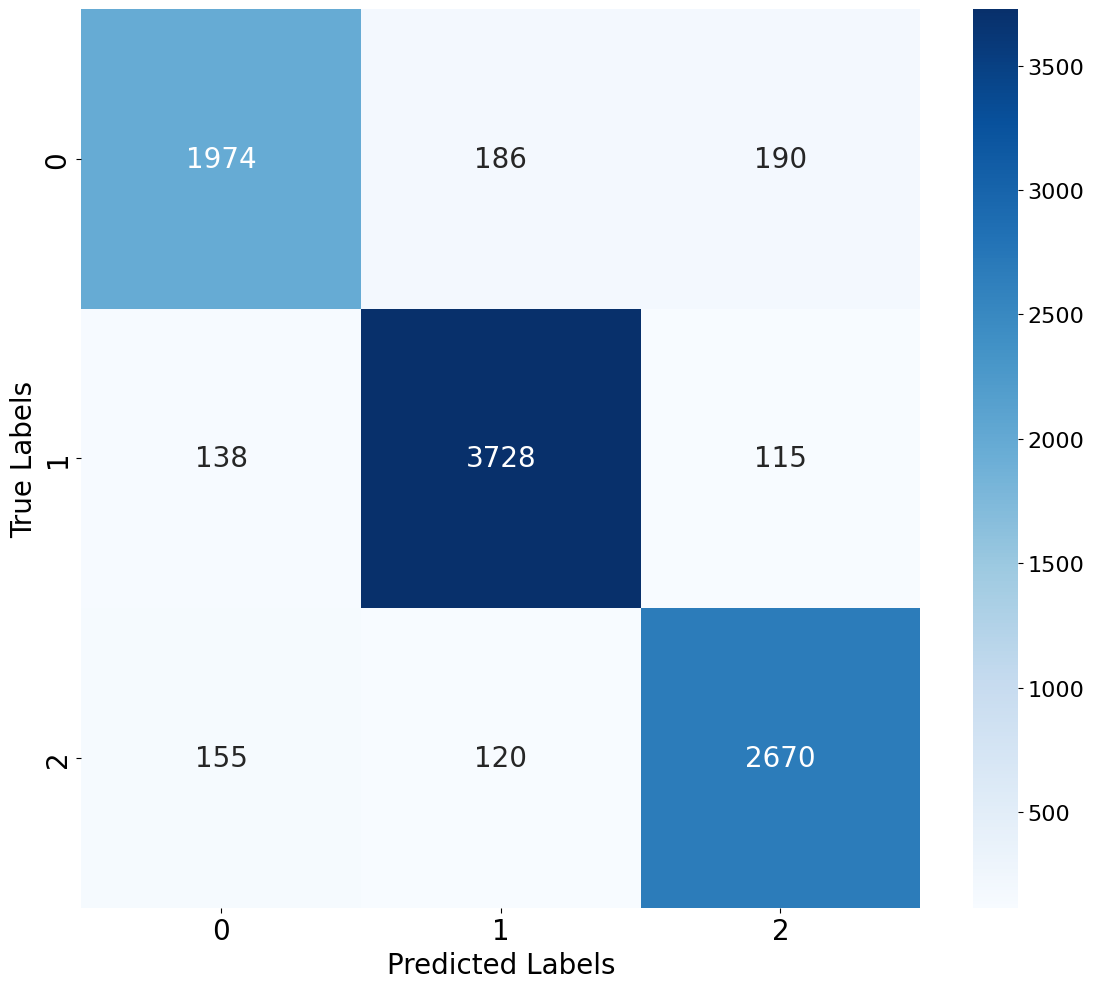

In [41]:
import torch
from torch.utils.data import DataLoader
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import confusion_matrix, roc_curve, auc
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.preprocessing import label_binarize
from itertools import cycle
from transformers import ElectraModel, ElectraTokenizer, ElectraForSequenceClassification

import torch

PATH = './model/'
device = torch.device('cuda')
model = torch.load(PATH + 'model_bloom_0808.pt')
model.load_state_dict(torch.load(PATH + 'model_state_dict_bloom_0808.pt'))
model.to(device)

# 데이터 로더 설정
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)  # 배치 크기 조정 가능

# 모델 평가 모드 설정
model.eval()

# 예측과 실제 레이블을 수집
true_labels = []
pred_labels = []

with torch.no_grad():
    for batch in test_loader:
        inputs = {key: val.to(device) for key, val in batch.items() if key != 'labels' and key != 'token_type_ids'}
        labels = batch['labels'].to(device)
        outputs = model(**inputs)
        logits = outputs.logits
        predictions = torch.argmax(logits, dim=1)
        
        true_labels.extend(labels.cpu().numpy())
        pred_labels.extend(predictions.cpu().numpy())

# 혼돈행렬 생성
cm = confusion_matrix(true_labels, pred_labels)

# 혼돈행렬 시각화 및 저장
plt.figure(figsize=(11.5, 10))  # 1.15:1 비율
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 20})  # 셀 안 숫자 크기

# 축, 제목 스타일 조정
plt.xlabel('Predicted Labels', fontsize=20)
plt.ylabel('True Labels', fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)  # ← 이 줄이 핵심

# 레이아웃 정리 후 저장
plt.tight_layout()
plt.savefig('confusion_matrix_bloomz(d).pdf', format='pdf')
plt.show()

C:\Users\kimdd\AppData\Local\Temp\ipykernel_12740\854109250.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


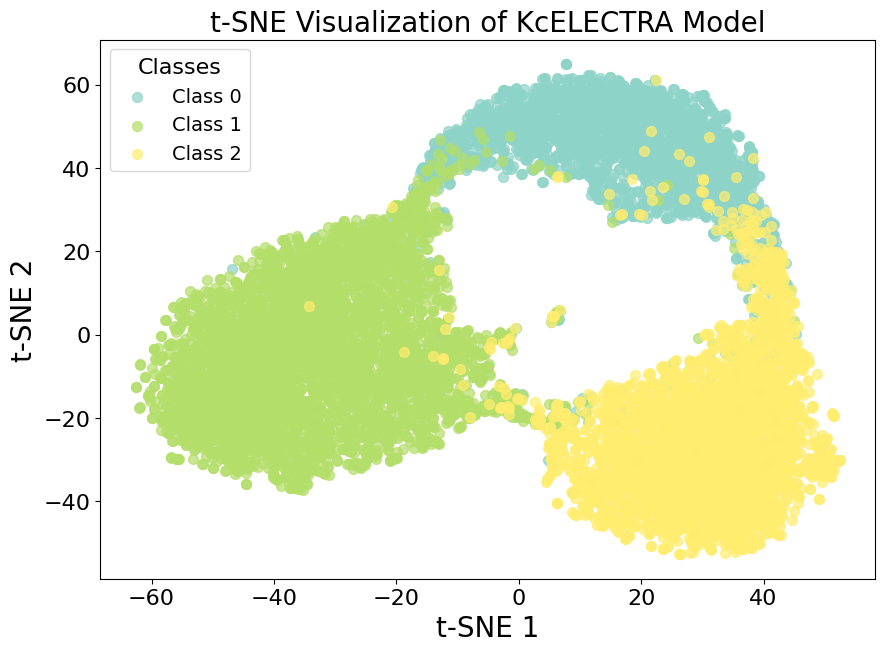

In [45]:
import torch
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import label_binarize
from transformers import ElectraModel, ElectraTokenizer, ElectraForSequenceClassification

PATH = './model/'
device = torch.device('cuda')
model = torch.load(PATH + 'model_0730.pt')
model.load_state_dict(torch.load(PATH + 'model_state_dict_0730.pt'))
model.to(device)
model.config.output_hidden_states = True

# 데이터 로더 설정
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)  # 배치 크기 조정 가능

# 모델 평가 모드 설정
model.eval()

# 예측과 실제 레이블을 수집
true_labels = []
features = []

with torch.no_grad():
    for batch in test_loader:
        inputs = {key: val.to(device) for key, val in batch.items() if key != 'labels'}
        labels = batch['labels'].to(device)
        
        outputs = model(**inputs)
        
        # Extract the hidden states
        hidden_states = outputs.hidden_states  # Assuming hidden states are returned
        embeddings = hidden_states[-1][:, 0, :]  # CLS token for sequence classification
        
        features.append(embeddings.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

# Convert features list to numpy array
features = np.vstack(features)

# Apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(features)

# Plot the t-SNE results
plt.figure(figsize=(10, 7))

# List of unique labels
unique_labels = np.unique(true_labels)

# Plot each class separately with different color using a color map
colors = plt.cm.Set3(np.linspace(0, 1, len(unique_labels)))

for i, label in enumerate(unique_labels):
    idx = np.where(true_labels == label)
    plt.scatter(tsne_results[idx, 0], tsne_results[idx, 1], label=f'Class {label}', s=50, alpha=0.7, color=colors[i])

plt.legend(title="Classes", prop={'size': 14}, title_fontsize = 16)  # Add legend to the plot with a title
plt.title('t-SNE Visualization of KcELECTRA Model', fontsize=20)
plt.xlabel('t-SNE 1', fontsize=20)
plt.ylabel('t-SNE 2', fontsize=20)

# Adjust xticks and yticks size
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.savefig('tsne_visualization.pdf', format='pdf')

plt.show()

OCR 활용

In [1]:
from imutils.perspective import four_point_transform
import matplotlib.pyplot as plt
import pytesseract
import imutils
import cv2
import re
import requests
import numpy as np

from imutils.perspective import four_point_transform
from imutils.contours import sort_contours
import matplotlib.pyplot as plt
import pytesseract
import imutils
import cv2
import re
import requests
import numpy as np
from PIL import Image

In [2]:
pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'
path = './ocr_test2.jpg'
image = cv2.imread(path)
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

text = pytesseract.image_to_string(rgb_image, lang='kor+eng')
print(text)

y - wesTPoRT, CT 06880

yHOLE FOODS MARKE
399 post RD WEST 7 ;

203) 227-6858

BACON LS NP
pacon LS N

BACON LS  NP
pacon tS X

365




In [3]:
def plt_imshow(title='image', img=None, figsize=(8 ,5)):
    plt.figure(figsize=figsize)
 
    if type(img) == list:
        if type(title) == list:
            titles = title
        else:
            titles = []
 
            for i in range(len(img)):
                titles.append(title)
 
        for i in range(len(img)):
            if len(img[i].shape) <= 2:
                rgbImg = cv2.cvtColor(img[i], cv2.COLOR_GRAY2RGB)
            else:
                rgbImg = cv2.cvtColor(img[i], cv2.COLOR_BGR2RGB)
 
            plt.subplot(1, len(img), i + 1), plt.imshow(rgbImg)
            plt.title(titles[i])
            plt.xticks([]), plt.yticks([])
 
        plt.show()
    else:
        if len(img.shape) < 3:
            rgbImg = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        else:
            rgbImg = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
 
        plt.imshow(rgbImg)
        plt.title(title)
        plt.xticks([]), plt.yticks([])
        plt.show()

Successfully opened ./sample.png


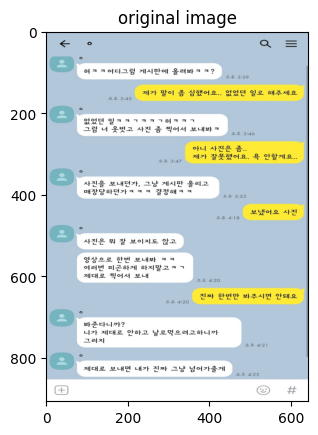

In [4]:
path = "./sample.png"

# 이미지 읽기
org_image = cv2.imread(path, cv2.IMREAD_COLOR)

if org_image is None:
    print(f"Error: Unable to open {path}")
else:
    print(f"Successfully opened {path}")


def plt_show(title, image):
    # BGR 색상 공간을 RGB 색상 공간으로 변환하고 이미지 표시하기 위한 함수 
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image)
    plt.title(title)
    plt.grid(False)
    plt.show()

plt_show("original image", org_image)

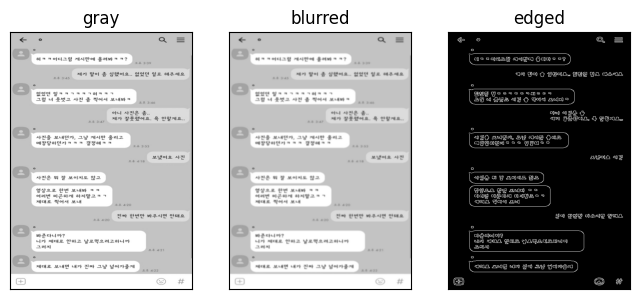

In [5]:
image = org_image.copy()
image = imutils.resize(image, width = 500)
ratio = org_image.shape[1] / float(image.shape[1])

# 이미지를 grayscale로 변환하고 blur를 적용
# 모서리를 찾기위한 이미지 연산

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5,), 0)
edged = cv2.Canny(blurred, 75, 200)
 
plt_imshow(['gray', 'blurred', 'edged'], [gray, blurred, edged])

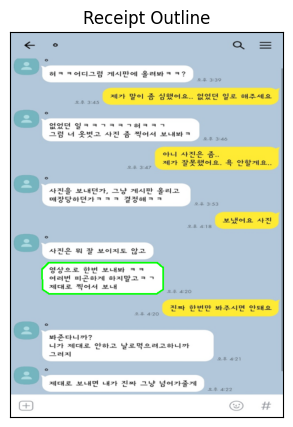

In [6]:
# contours를 찾아 크기순으로 정렬
cnts = cv2.findContours(edged.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = imutils.grab_contours(cnts)
cnts = sorted(cnts, key=cv2.contourArea, reverse=True)
 
receiptCnt = []
 
# 정렬된 contours를 반복문으로 수행하며 4개의 꼭지점을 갖는 도형을 검출
for c in cnts:
	peri = cv2.arcLength(c, True)
	approx = cv2.approxPolyDP(c, 0.01 * peri, True)
 
	# contours가 크기순으로 정렬되어 있기때문에 제일 첫번째 사각형을 영수증 영역으로 판단하고 break
	if len(approx) >= 4:
		receiptCnt = approx
		break
		
		
 
 
# 만약 추출한 윤곽이 없을 경우 오류
if receiptCnt is None:
	raise Exception(("Could not find receipt outline."))
    
output = image.copy()
cv2.drawContours(output, [receiptCnt], -1, (0, 255, 0), 2)
plt_imshow("Receipt Outline", output)



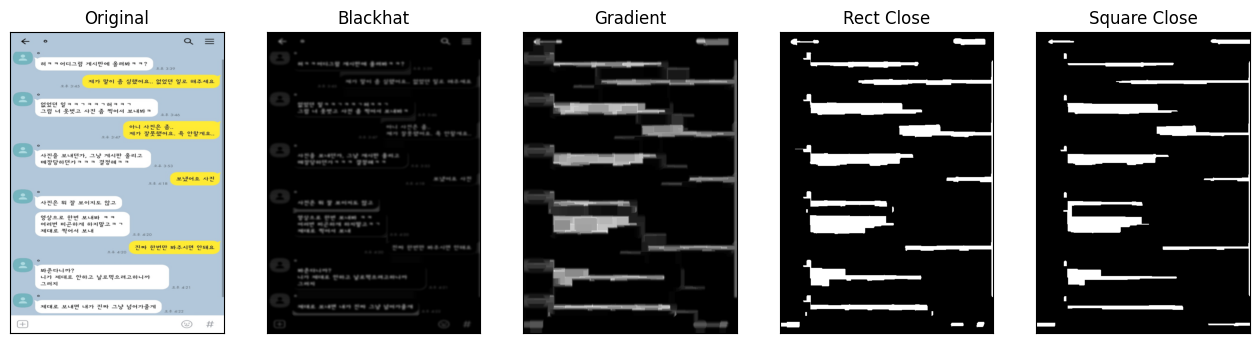

In [7]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
(H, W) = gray.shape
 
rectKernel = cv2.getStructuringElement(cv2.MORPH_RECT, (30, 20))
sqKernel = cv2.getStructuringElement(cv2.MORPH_RECT, (50, 21))
 
gray = cv2.GaussianBlur(gray, (11, 11), 0)
blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, rectKernel)
 
grad = cv2.Sobel(blackhat, ddepth=cv2.CV_32F, dx=1, dy=0, ksize=-1)
grad = np.absolute(grad)
(minVal, maxVal) = (np.min(grad), np.max(grad))
grad = (grad - minVal) / (maxVal - minVal)
grad = (grad * 255).astype("uint8")
 
grad = cv2.morphologyEx(grad, cv2.MORPH_CLOSE, rectKernel)
thresh = cv2.threshold(grad, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]
 
close_thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, sqKernel)
close_thresh = cv2.erode(close_thresh, None, iterations=2)
 
plt_imshow(["Original", "Blackhat", "Gradient", "Rect Close", "Square Close"], [image, blackhat, grad, thresh, close_thresh], figsize=(16, 10))

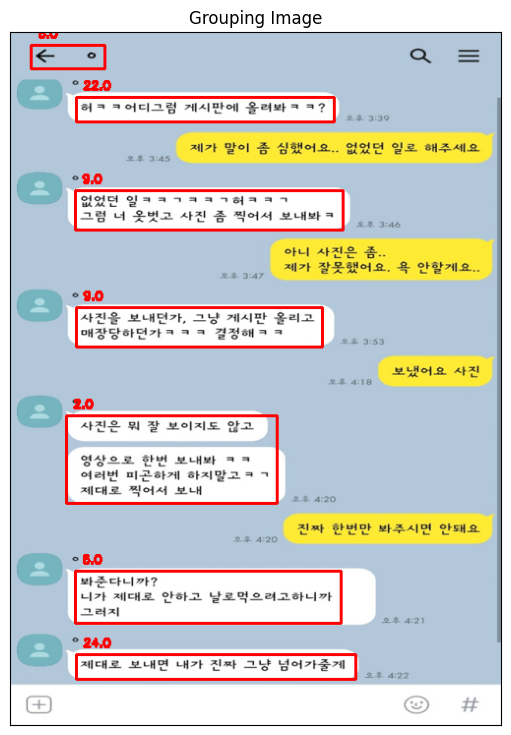

In [8]:
# Convert image to HSV color space
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define range of yellow color in HSV
lower_yellow = np.array([20, 100, 100])
upper_yellow = np.array([30, 255, 255])

# Threshold the HSV image to get only yellow colors
mask_y = cv2.inRange(hsv, lower_yellow, upper_yellow)

# Bitwise-AND mask and original image
res_y = cv2.bitwise_and(image,image, mask= mask_y)

# Convert the result to grayscale 
gray_res = cv2.cvtColor(res_y,cv2.COLOR_BGR2GRAY) 

# Apply adaptive thresholding to convert the grayscale image to binary and improve OCR results 
binary_res = cv2.adaptiveThreshold(gray_res,maxValue=255,
                                   adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   thresholdType=cv2.THRESH_BINARY_INV,
                                   blockSize=91,C=12)

kernel=np.ones((5 ,5),np.uint8) 
dilated_img=cv2.dilate(binary_res,kernel ,iterations=1) 


cnts = cv2.findContours(close_thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = imutils.grab_contours(cnts)
cnts = sort_contours(cnts, method="top-to-bottom")[0]

roi_list = []
roi_title_list = []

result = []
 
margin = 7
receipt_grouping = image.copy()
receipt_grouping_y = res_y.copy() 

for c in cnts:
  (x, y, w, h) = cv2.boundingRect(c)
  ar = w // float(h)

 
  if ar > 3.0 and ar < 6.5 and (W/2) < x:
    color = (0, 255, 0)
    roi = image[y - margin:y + h + margin, x - margin:x + w + margin]
    roi_list.append(roi)
    roi_title_list.append("Roi_{}".format(len(roi_list)))

  else:
    color = (0, 0, 255)

# and ar != 5.0
# ar != 0.0 and ar != 25.0
  if ar != 0.0 and ar != 1.0 and ar != 7.0 and ar != 5.0 and ar != 21.0 and ar != 12.0:
    cv2.rectangle(receipt_grouping, (x - margin, y - margin), (x + w + margin, y + h + margin), color, 2)
    cv2.putText(receipt_grouping, "".join(str(ar)), (x, y - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 2)
    
    color = (255, 0, 0)
    roi=image[y - margin:y + h + margin, x - margin:x + w + margin]
    roi_list.append(roi)
    roi_title_list.append("Roi_{}".format(len(roi_list)))
  
plt_imshow(["Grouping Image"], [receipt_grouping], figsize=(16, 9))

custom_config = r'--oem 3 --psm 6'
text = pytesseract.image_to_string(receipt_grouping, lang='kor+hangul', config = custom_config)
text2 = pytesseract.image_to_string(binary_res, lang='kor+hangul', config = custom_config)

result.extend(text.split('\n'))
result.extend(text2.split('\n'))


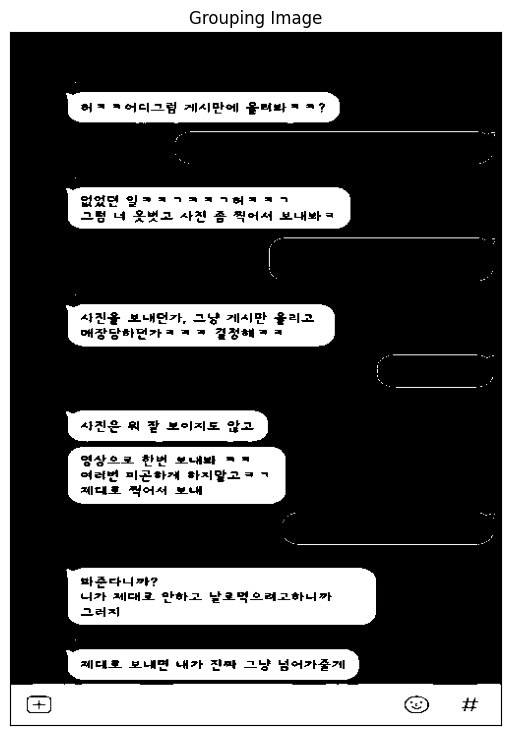

In [9]:
cnts = cv2.findContours(close_thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = imutils.grab_contours(cnts)
cnts = sort_contours(cnts, method="top-to-bottom")[0]

# Convert image to HSV color space
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define range of yellow color in HSV
lower_white = np.array([0, 0, 200])
upper_white = np.array([180, 25, 255])

# Threshold the HSV image to get only yellow colors
mask_y = cv2.inRange(hsv, lower_white, upper_white)

# Bitwise-AND mask and original image
res_y = cv2.bitwise_and(image,image, mask= mask_y)

# Convert the result to grayscale 
gray_res = cv2.cvtColor(res_y,cv2.COLOR_BGR2GRAY) 

# Apply adaptive thresholding to convert the grayscale image to binary and improve OCR results 
binary_res = cv2.adaptiveThreshold(gray_res,maxValue=255,
                                   adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   thresholdType=cv2.THRESH_BINARY_INV,
                                   blockSize=91,C=12)



custom_config = r'--oem 3 --psm 6'
text2 = pytesseract.image_to_string(mask_y, lang='kor+hangul', config = custom_config)
plt_imshow(["Grouping Image"], [mask_y], figsize=(16, 9))


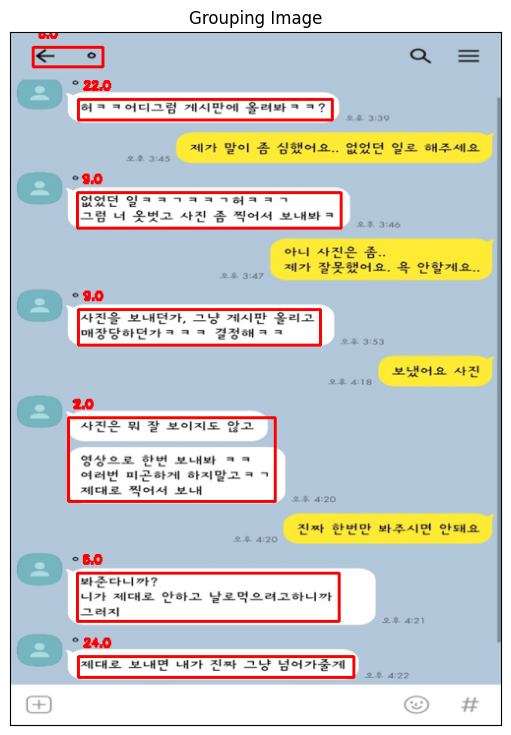

In [10]:
cnts = cv2.findContours(close_thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = imutils.grab_contours(cnts)
cnts = sort_contours(cnts, method="top-to-bottom")[0]


roi_list = []
roi_title_list = []
result = []
 
margin = 5
receipt_grouping = image.copy() 


for c in cnts:
  (x, y, w, h) = cv2.boundingRect(c)
  ar = w // float(h)
  
 
  if ar > 3.0 and ar < 6.5 and (W/2) < x:
    color = (0, 255, 0)
    roi = image[y - margin:y + h + margin, x - margin:x + w + margin]
    roi_list.append(roi)
    roi_title_list.append("Roi_{}".format(len(roi_list)))

  else:
    color = (0, 0, 255)
 
  if ar != 0.0 and ar != 1.0 and ar != 7.0 and ar != 5.0 and ar != 21.0 and ar != 12.0:
    cv2.rectangle(receipt_grouping, (x - margin, y - margin), (x + w + margin, y + h + margin), color, 2)
    cv2.putText(receipt_grouping, "".join(str(ar)), (x, y - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 2)
  
plt_imshow(["Grouping Image"], [receipt_grouping], figsize=(16, 9))

custom_config = r'--oem 3 --psm 6'
text = pytesseract.image_to_string(receipt_grouping, lang='kor+hangul', config = custom_config)
result.extend(text.split('\n'))

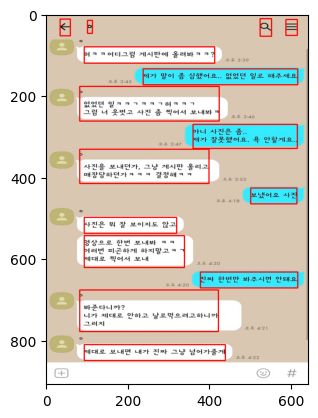

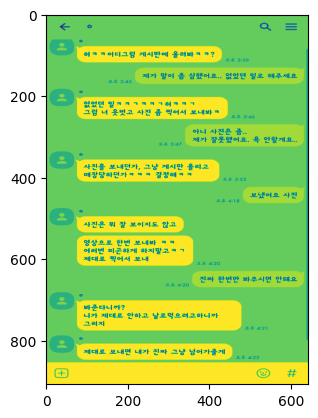

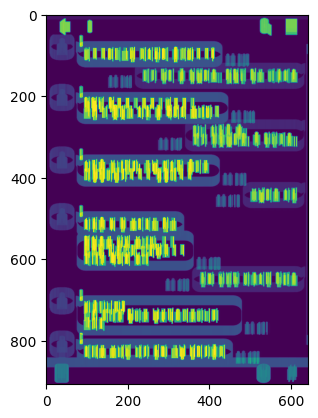

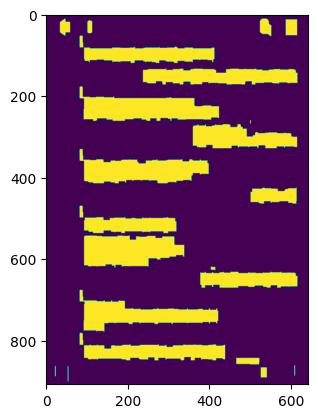

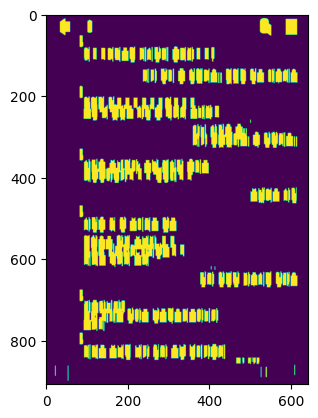

['제대로 보내면 내가 진짜 그냥 넘어카줄게', '봐준다니까?', '니카 제대로 안하고 날로먹으려고하니까', '그러지', '진짜 한번만 봐주시면 안돼요', '영상으로 한번 보내봐 ㅋㅋ', '영상     한번', '여러번 피곤하게 하지말고 ㅋㄱ', '제대로 찍어서 보내', '사진은 뭐 잘 보이지도 않고', '보냈어요 사진', '사진을 보내던카, 그냥 게시판 올리고', '매장당하던가ㅋㅋㅋ 결정해ㅋㅋ', '아니 사진은 좀……', '제가 잘못했어요. 욕 안할게요..', '없었던 일ㅋㅋㄱㅋㅋㅋㄱ혀ㅋㅋㅋ', '그럼 너 옷벗고 사진 좀 찍어서 보내봐ㅋ', '제카 말이 좀 심했어요.. 없었던 일로 해주세요', '허ㅋㅋ어디그럼 게시판에 올려봐ㅋㅋㅎ']


In [11]:
# -*- coding: utf-8 -*-
import cv2
import numpy as np
import re

# Opencv로 단어뭉치로 추정되는 것들을 추출하는 과정
# 1. 이미지 흑백처리 (gray)
# 2. 이미지 경계부분 찾기(morph) - dilation(팽창), erosion(침식) 등 있지만 gradient(dilate 와 erosion 결과의 차) 방법 사용
# 3. 진한 경계부분만 추출 (thr)
# 4. 경계부분을 옆으로 번지게 하기 (글자라는 것을 확실히 하기 위해 closing 연산을 통해 선을 번지게)
# 5. 그 중 뭉텅이로 있는 부분을 추출

def selectWords(img):
    # org = cv2.imread('capture4.png', cv2.IMREAD_COLOR)
    org = img
    # org = cv2.resize(org, dsize=(0,0), fx=0.5, fy=0.5)
    gray = cv2.cvtColor(org, cv2.COLOR_BGR2GRAY)  # ================  1 gray scale로 변환

    kernel = np.ones((25, 2), np.uint8)
    kernel2 = np.ones((6, 15), np.uint8)
    roi_list = []
    text_list = []

    morph = cv2.morphologyEx(gray, cv2.MORPH_GRADIENT, kernel)  # 2 ================ 경계선 찾기

    _, thr = cv2.threshold(morph, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)  # 3 ================ 임계처리

    morph2 = cv2.morphologyEx(thr, cv2.MORPH_CLOSE, kernel2)  # 4 ================ 뭉게기

    contours, _ = cv2.findContours(morph2, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)  # 5 ================ 특징점 찾기

    org2 = cv2.copyMakeBorder(org, 0, 0, 0, 0, cv2.BORDER_REPLICATE)
    for cnt in contours:
        try:
            x, y, w, h = cv2.boundingRect(cnt)
            if w > 5 and 30 < h < 500:
                # print(w, h)
                roi = org2[y:y + h, x:x + w]
                # cv2.imshow('roi', roi)
                roi_list.append(roi)
                cv2.rectangle(org, (x, y), (x+w, y+h), (255, 0, 0), 2)

                # 이미지를 흑백으로 변환
                gray_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    
                # 이미지에서 텍스트 추출
                custom_config = r'--oem 3 --psm 6'
                text = pytesseract.image_to_string(gray_roi, lang='kor+hangul', config = custom_config)

                # 추출된 텍스트 출력 또는 저장
                text_list.append(text)

        except Exception as e:
           pass

    cnt = 0              # print all pieces
    '''for r in roi_list:
        cnt += 1
        cv2.imshow(str(cnt), r)'''

    plt.imshow(org)
    plt.show()
    plt.imshow(gray)
    plt.show()
    plt.imshow(morph)
    plt.show()
    plt.imshow(morph2)
    plt.show()
    plt.imshow(thr)
    plt.show()

    return org, roi_list, gray, morph, thr, morph2, text_list

# 이미지 읽기
img = cv2.imread('./sample.png', cv2.IMREAD_COLOR)

# selectWords() 호출 및 결과 받기
org, roi_list, gray, morph, thr, morph2, text_list = selectWords(img)

filtered_results=[]
for txt in text_list: 
    if re.search("[가-힣]",txt): 
        lines=txt.split('\n')
        for line in lines:
            line = line.strip()
            # "오전" 또는 "오후" 다음에 시간 형식이 오는 문자열 찾기
            if re.search(r"(오전|오후)\s*\d+", line):
                continue
            if re.fullmatch(r"[\d\s:]+", line):
                continue
            if re.search(r"[@>#|%]", line):
                continue
            if line and len(line) > 1: 
                filtered_results.append(line) 

print(filtered_results)


Successfully opened ./sample9.jpg


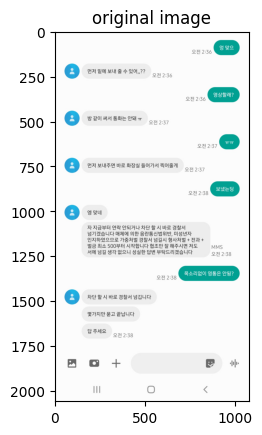

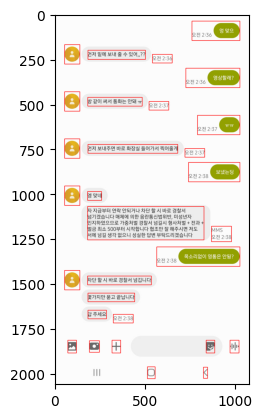

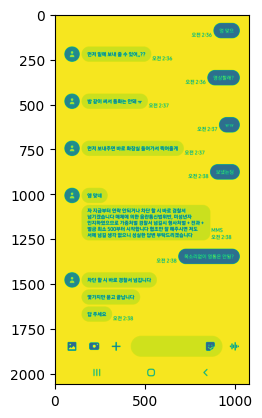

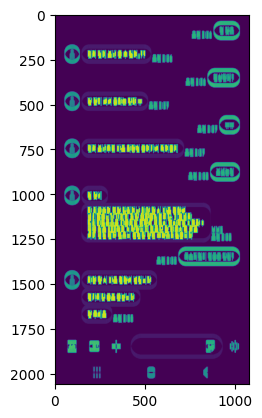

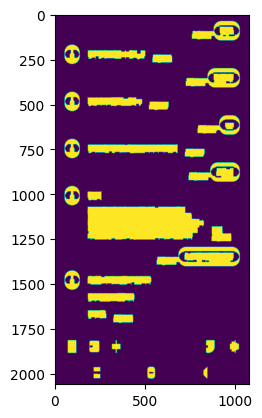

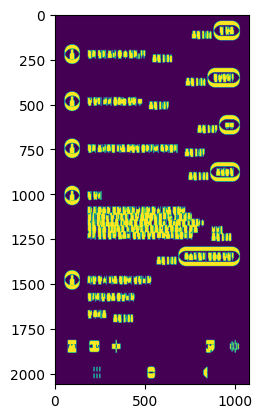

PDF 파일이 저장되었습니다: output.pdf


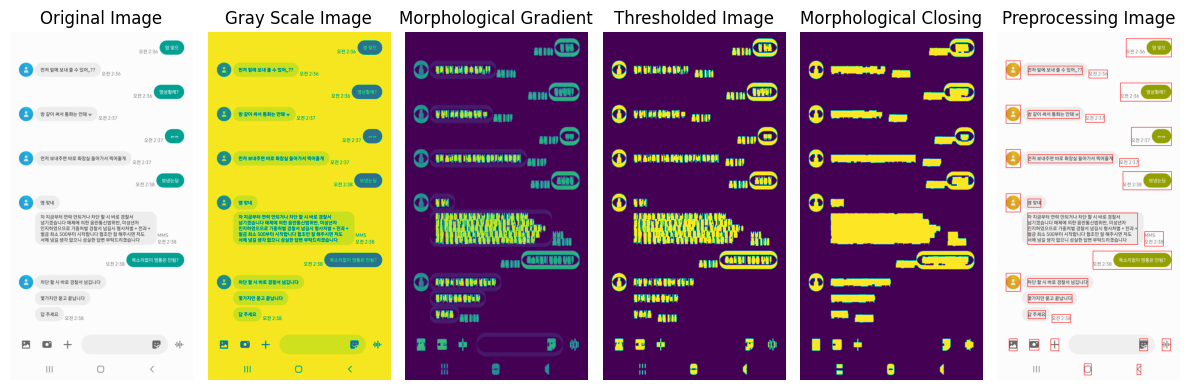

In [ ]:
import matplotlib.pyplot as plt
import cv2

# 이미지 읽기
path = "./sample9.jpg"
org_image = cv2.imread(path, cv2.IMREAD_COLOR)

if org_image is None:
    print(f"Error: Unable to open {path}")
else:
    print(f"Successfully opened {path}")


def plt_show(title, image):
    # BGR 색상 공간을 RGB 색상 공간으로 변환하고 이미지 표시하기 위한 함수 
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image)
    plt.title(title)
    plt.grid(False)
    plt.show()

plt_show("original image", org_image)

# 이미지를 플로팅하는 함수
def plot_images(images, titles=None, cmap=None):
    num_images = len(images)
    if titles is None:
        titles = ['Image {}'.format(i+1) for i in range(num_images)]
    elif len(titles) != num_images:
        raise ValueError("Number of titles does not match number of images")

    plt.figure(figsize=(12, 8))
    for i in range(num_images):
        plt.subplot(1, num_images, i+1)
        plt.imshow(images[i], cmap=cmap)
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()

# 이미지를 저장하는 함수
def save_images_to_pdf(images, titles=None, filename='output.pdf'):
    plot_images(images, titles)
    plt.savefig(filename, format='pdf', dpi = 500)
    print("PDF 파일이 저장되었습니다:", filename)

# 이미지 읽기
img = cv2.imread('./sample9.jpg', cv2.IMREAD_COLOR)

# selectWords() 호출 및 결과 받기
org, roi_list, gray, morph, thr, morph2, text_list = selectWords(img)

img = cv2.imread('./sample9.jpg', cv2.IMREAD_COLOR)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 저장할 이미지 목록과 제목 설정
images_to_save = [img, gray, morph, thr, morph2, org]
titles = ['Original Image','Gray Scale Image', 'Morphological Gradient', 'Thresholded Image', 'Morphological Closing', 'Preprocessing Image',]

# PDF 파일로 저장
save_images_to_pdf(images_to_save, titles, filename='output.pdf')

In [12]:
filtered_results

['제대로 보내면 내가 진짜 그냥 넘어카줄게',
 '봐준다니까?',
 '니카 제대로 안하고 날로먹으려고하니까',
 '그러지',
 '진짜 한번만 봐주시면 안돼요',
 '영상으로 한번 보내봐 ㅋㅋ',
 '영상     한번',
 '여러번 피곤하게 하지말고 ㅋㄱ',
 '제대로 찍어서 보내',
 '사진은 뭐 잘 보이지도 않고',
 '보냈어요 사진',
 '사진을 보내던카, 그냥 게시판 올리고',
 '매장당하던가ㅋㅋㅋ 결정해ㅋㅋ',
 '아니 사진은 좀……',
 '제가 잘못했어요. 욕 안할게요..',
 '없었던 일ㅋㅋㄱㅋㅋㅋㄱ혀ㅋㅋㅋ',
 '그럼 너 옷벗고 사진 좀 찍어서 보내봐ㅋ',
 '제카 말이 좀 심했어요.. 없었던 일로 해주세요',
 '허ㅋㅋ어디그럼 게시판에 올려봐ㅋㅋㅎ']

In [ ]:
import torch
import torch.nn.functional as F
from transformers import ElectraModel, ElectraTokenizer, ElectraForSequenceClassification
from transformers import AutoTokenizer
import pandas as pd

PATH = './model/'
device = torch.device('cuda')
model = torch.load(PATH + 'model_0730.pt')
model.load_state_dict(torch.load(PATH + 'model_state_dict_0730.pt'))
model.to(device)

def sentence_predict(sent):
    model.eval()

    MODEL_NAME = "beomi/KcELECTRA-base-v2022"
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    # 모델과 토크나이저 로드 (미리 로드되어 있다고 가정)
    # model = ElectraForSequenceClassification.from_pretrained("kcelectra-model-name")
    # tokenizer = ElectraTokenizer.from_pretrained("kcelectra-tokenizer-name")

    tokenized_sent = tokenizer(sent,
                               return_tensors='pt',
                               truncation=True,
                               add_special_tokens=True,
                               padding=True,
                               max_length=128)

    tokenized_sent.to(device)

    with torch.no_grad():
        outputs = model(input_ids=tokenized_sent["input_ids"],
                        attention_mask=tokenized_sent["attention_mask"],
                        token_type_ids=tokenized_sent["token_type_ids"]
                        )

    logits = outputs[0]
    logits = logits.detach().cpu().numpy()[0]
    
    labels = ["성적인 발언", "정상 발언", "혐오 발언"]

    result_str = f"입력 문장: {sent}"
    
    #for i, logit in enumerate(logits):
    #    if i == 0 or i == 1 or i == 2:
    #        logit = max(0, logit)  # 음수인 경우 0으로 바꾸기
        #result_str += f"Class {i} Logit: {logit:.4f}\n"
    
    predicted_class = logits.argmax()
    result_str += f"예측 결과: {labels[predicted_class]}"

    # 각 클래스에 대한 백분율 계산
    #total_sum = sum([max(0, logit) for logit in logits[:3]])  # 음수인 경우 0으로 바꾼 값의 합
    #percentages = [(max(0, logit) / total_sum) * 100 for logit in logits[:3]]
    #for i, percent in enumerate(percentages):
    #    result_str += f"\nClass {i}: {percent:.2f}%"

    return result_str


sentences = []
predictions = []

for sentence in filtered_results:
    result_str = sentence_predict(sentence)
    sentences.append(sentence)  # 입력문장 저장
    predictions.append(result_str.split(": ")[-1])

df = pd.DataFrame(data={'Sentence': sentences, 'Prediction': predictions})
print(df)

In [51]:
import pandas as pd

# 데이터프레임 생성
df = pd.DataFrame(filtered_results, columns=['ocr_text'])

# csv 파일로 저장
df.to_csv('filtered_results.csv', index=False)

In [ ]:
import pandas as pd

def levenshtein_distance(str1, str2):
    d = {}
    len_str1 = len(str1)
    len_str2 = len(str2)
    for i in range(-1,len_str1+1):
        d[(i,-1)] = i+1
    for j in range(-1,len_str2+1):
        d[(-1,j)] = j+1

    for i in range(len_str1):
        for j in range(len_str2):
            if str1[i] == str2[j]:
                cost = 0
            else:
                cost = 1
            d[(i,j)] = min(
                           d[(i-1,j)] + 1, # deletion
                           d[(i,j-1)] + 1, # insertion
                           d[(i-1,j-1)] + cost, # substitution
                          )
            if i and j and str1[i]==str2[j-1] and str1[i-1] == str2[j]:
                d[(i,j)] = min (d[(i,j)], d[i-2,j-2] + cost) # transposition

    return d[len_str1-1,len_str2-1]

# 텍스트 파일에서 원본 텍스트 불러오기
with open('real2.txt', 'r', encoding='utf-8') as f:
    original_text = f.readlines()

# 데이터프레임에서 OCR 텍스트 가져오기
df = pd.read_csv('filtered_results.csv')  # filtered_results 데이터프레임 불러오기
ocr_text = df['ocr_text'].values  # 'ocr_text'는 데이터프레임의 컬럼 이름이며, 이를 사용자의 데이터에 맞게 수정해야 합니다.

# 원본 텍스트와 OCR 텍스트를 순차적으로 비교하며 레벤슈타인 거리 계산
distances = []
for original_text, ocr_text in zip(original_text, ocr_text):
    distance = levenshtein_distance(original_text, ocr_text)
    distances.append(distance)

# 레벤슈타인 거리의 평균 계산
average_distance = sum(distances) / len(distances) if distances else 0
print(average_distance)

4.266666666666667
